# Sentiment Analysis on Movie Reviews

## 1. Project Introduction

### Objective

The objective of this project is to develop a machine learning model that classifies movie reviews as either Positive or Negative based on their textual content.

### Dataset

The project uses the IMDb Movie Reviews dataset containing 50,000 labelled movie reviews.

### Dataset Features

* `review`: Textual content of the movie review.
* `sentiment`: Sentiment label (Positive or Negative).

### Project Workflow

1. Exploratory Data Analysis
2. Data Cleaning and Text Preprocessing
3. Feature Extraction using TF-IDF
4. Machine Learning Model Development
5. Model Evaluation and Comparison
6. Hyperparameter Tuning
7. Prediction Application using Streamlit


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configure visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Define project paths
PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "IMDB Dataset.csv"
IMAGE_DIR = PROJECT_ROOT / "images"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Project Root:", PROJECT_ROOT)
print("Dataset Path:", DATASET_PATH)

Libraries imported successfully.
Project Root: m:\GEN AI\Cloudcredits\Cloudcredits\02_Sentiment_Analysis
Dataset Path: m:\GEN AI\Cloudcredits\Cloudcredits\02_Sentiment_Analysis\data\raw\IMDB Dataset.csv


In [2]:
# Load the IMDb dataset
df = pd.read_csv(DATASET_PATH)

# Display the first five records
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (50000, 2)

Column Names:
['review', 'sentiment']

Data Types:
review       str
sentiment    str
dtype: object


## 2. Dataset Overview

The IMDb dataset contains 50,000 movie reviews labelled as either Positive or Negative.

The dataset consists of two columns:

* **review:** Contains the actual textual movie review.
* **sentiment:** Represents the corresponding sentiment classification.

The dataset will be examined for missing values, duplicate records, data types, and class distribution before preprocessing.


In [4]:
# Dataset information
print("Dataset Information:")
df.info()

# Statistical overview
print("\nDataset Description:")
display(df.describe(include="all"))

# Missing values
print("\nMissing Values:")
display(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Sentiment distribution
print("\nSentiment Distribution:")
display(df["sentiment"].value_counts())

# Sentiment percentages
print("\nSentiment Percentages:")
display(df["sentiment"].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB

Dataset Description:


,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000



Missing Values:


review       0
sentiment    0
dtype: int64


Duplicate Records: 418

Sentiment Distribution:


sentiment
positive    25000
negative    25000
Name: count, dtype: int64


Sentiment Percentages:


sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64

In [ ]:
## 3. Sentiment Distribution

The sentiment distribution helps us understand the balance between positive and negative movie reviews.

Checking class distribution is important because an imbalanced dataset can influence model training and evaluation.

We will visualize the number and percentage of reviews belonging to each sentiment class.


sentiment
positive    25000
negative    25000
Name: count, dtype: int64

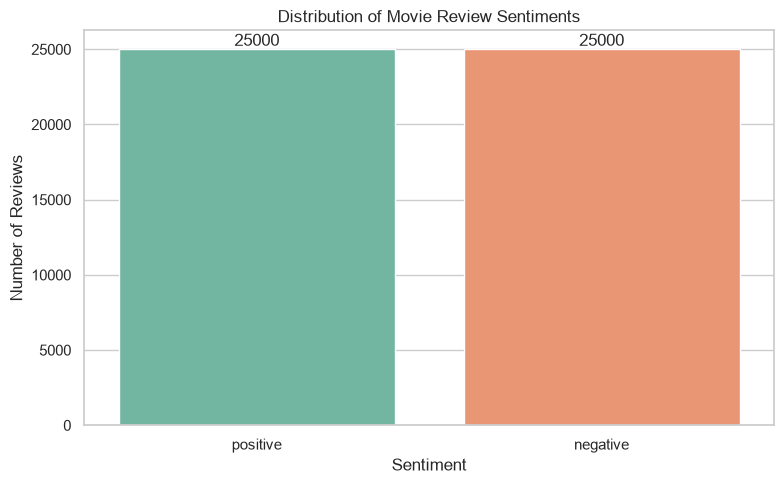

In [5]:
# Calculate sentiment counts
sentiment_counts = df["sentiment"].value_counts()

# Display counts
display(sentiment_counts)

# Plot sentiment distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    palette="Set2",
    legend=False
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Movie Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()

# Save visualization
plt.savefig(
    IMAGE_DIR / "01_sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings

* The dataset contains 25,000 positive reviews and 25,000 negative reviews.
* Both sentiment categories represent exactly 50% of the dataset.
* The dataset is perfectly balanced across the two sentiment classes.
* No class-balancing techniques, such as oversampling or undersampling, are required.

This balanced distribution provides a suitable foundation for training and evaluating binary sentiment classification models.

## 4. Review Length Analysis

Review length is an important characteristic of textual datasets.

Analyzing review length helps us understand the distribution of text, identify unusually short or long reviews, and make informed decisions about text preprocessing and feature extraction.

We will calculate review lengths using the number of characters in each review and visualize their distribution.

In [6]:
# Calculate review length in characters
df["review_length"] = df["review"].str.len()

# Display descriptive statistics
print("Review Length Statistics:")
display(df["review_length"].describe())

Review Length Statistics:


count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review_length, dtype: float64

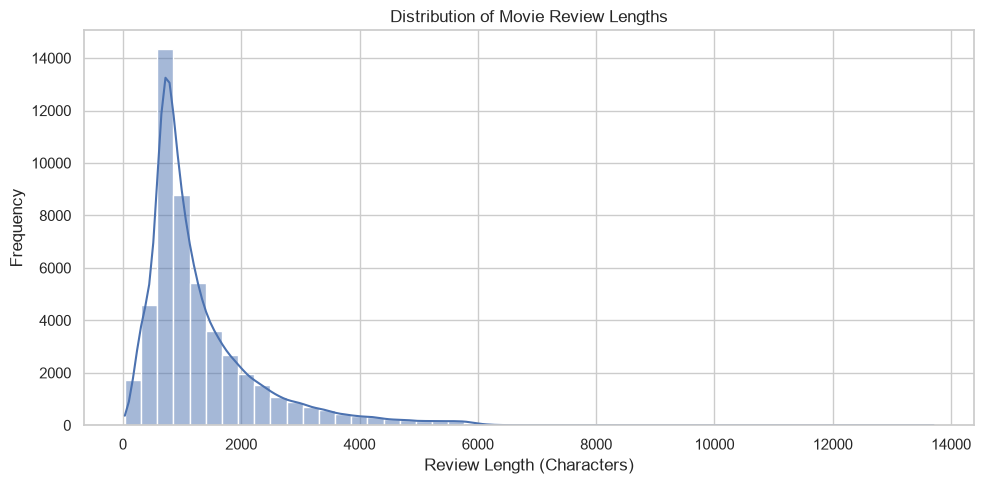

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="review_length",
    bins=50,
    kde=True
)

plt.title("Distribution of Movie Review Lengths")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "02_review_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings

* The review-length distribution is positively skewed (right-skewed).
* Most reviews contain approximately 500–1,000 characters.
* The distribution has a long right tail, indicating the presence of unusually long reviews.
* The mean review length (1,309 characters) is higher than the median (970 characters).
* Long reviews should not be automatically removed because they may contain useful information for sentiment classification.

The observed distribution highlights the importance of understanding text length before applying text preprocessing and feature extraction techniques.

## 5. Review Length by Sentiment

In this section, we compare the lengths of positive and negative movie reviews.

This analysis helps identify whether review length varies depending on sentiment and whether any noticeable patterns exist between the two categories.

We will use descriptive statistics and a box plot to compare both groups.

In [8]:
# Average review length by sentiment
print("Average Review Length by Sentiment:")

display(
    df.groupby("sentiment")["review_length"]
    .mean()
    .round(2)
)

# Median review length by sentiment
print("\nMedian Review Length by Sentiment:")

display(
    df.groupby("sentiment")["review_length"]
    .median()
    .round(2)
)

Average Review Length by Sentiment:


sentiment
negative    1294.06
positive    1324.80
Name: review_length, dtype: float64


Median Review Length by Sentiment:


sentiment
negative    973.0
positive    968.0
Name: review_length, dtype: float64

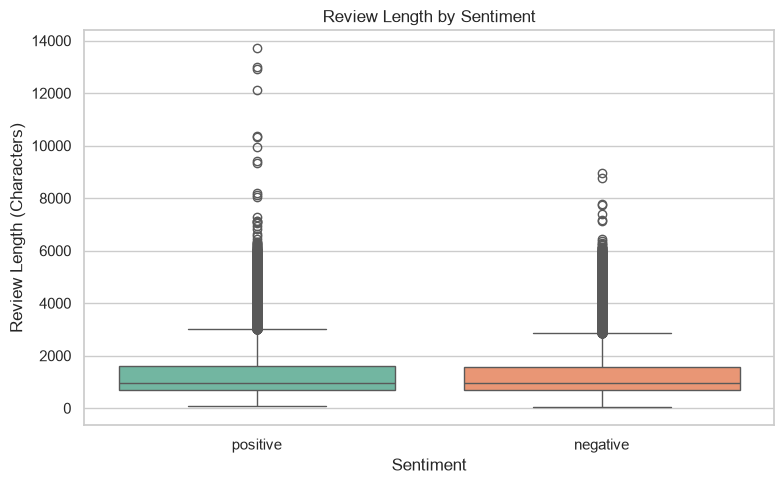

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="review_length",
    hue="sentiment",
    palette="Set2",
    legend=False
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Review Length (Characters)")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "03_review_length_by_sentiment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Numerical Findings

| Metric                | Negative Reviews | Positive Reviews |
| --------------------- | ---------------: | ---------------: |
| Average Review Length |         1,294.06 |         1,324.80 |
| Median Review Length  |              973 |              968 |

### Key Observations

* Positive reviews have a slightly higher average length than negative reviews.
* Negative reviews have a marginally higher median length.
* The differences between both sentiment categories are relatively small.
* Both categories exhibit numerous long-review outliers.

### Conclusion

The review-length distributions of positive and negative reviews are broadly similar. Therefore, review length alone is unlikely to be a strong predictor of sentiment. Text-based features and linguistic patterns will be more important for classification.

## 6. Text Characteristics Analysis

### 6.1 HTML Tags and Formatting Artifacts

The IMDb dataset contains HTML formatting elements originating from the original review content.

These elements do not directly represent sentiment and may introduce unnecessary noise during text processing.

We will identify reviews containing HTML tags and inspect examples to understand the type of formatting present.

In [10]:
import re

# Identify reviews containing HTML tags
html_mask = df["review"].str.contains(
    r"<[^>]+>",
    regex=True,
    na=False
)

html_reviews_count = html_mask.sum()

print("Total Reviews:", len(df))
print("Reviews Containing HTML Tags:", html_reviews_count)

print(
    "Percentage of Reviews Containing HTML Tags:",
    round(html_reviews_count / len(df) * 100, 2),
    "%"
)

# Display sample reviews containing HTML tags
print("\nSample Reviews Containing HTML Tags:\n")

for review in df.loc[html_mask, "review"].head(3):
    print(review[:500])
    print("\n" + "-" * 80)

Total Reviews: 50000
Reviews Containing HTML Tags: 29202
Percentage of Reviews Containing HTML Tags: 58.4 %

Sample Reviews Containing HTML Tags:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

--------------------------------------------------------------------------------
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not 

### Key Findings

* 29,202 out of 50,000 reviews contain HTML tags.
* Approximately 58.4% of the dataset contains HTML formatting artifacts.
* The `<br />` tag is frequently used to represent line breaks and paragraph separation.
* These formatting elements do not directly contribute to sentiment classification.

### Preprocessing Decision

HTML tags will be removed during text preprocessing to eliminate unnecessary formatting artifacts while retaining meaningful textual content.

In [11]:
# Analyze punctuation and special characters

import string

# Count punctuation characters in the entire dataset
total_punctuation = df["review"].apply(
    lambda text: sum(char in string.punctuation for char in text)
).sum()

# Calculate total characters
total_characters = df["review"].str.len().sum()

print("Total Punctuation Characters:", total_punctuation)

print(
    "Punctuation Percentage:",
    round(total_punctuation / total_characters * 100, 2),
    "%"
)

# Display sample reviews containing punctuation
print("\nSample Reviews:\n")

for review in df["review"].head(5):
    print(review[:300])
    print("-" * 80)

Total Punctuation Characters: 2628928
Punctuation Percentage: 4.02 %

Sample Reviews:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru
--------------------------------------------------------------------------------
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" 
--------------------------------------------------------------------------------
I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted com

### Key Findings

* The dataset contains 2,628,928 punctuation characters.
* Punctuation accounts for approximately 4.02% of the total review characters.
* Common punctuation includes periods, commas, apostrophes, exclamation marks, hyphens, and quotation marks.
* Apostrophes are frequently used in contractions and negation-related expressions.

### Preprocessing Considerations

Punctuation handling should preserve meaningful word boundaries and negation patterns. Special attention will be given to contractions and expressions that may influence sentiment classification.

In [12]:
# Calculate uppercase and lowercase character counts

total_uppercase = df["review"].apply(
    lambda text: sum(char.isupper() for char in text)
).sum()

total_lowercase = df["review"].apply(
    lambda text: sum(char.islower() for char in text)
).sum()

total_letters = total_uppercase + total_lowercase

print("Uppercase Characters:", total_uppercase)
print("Lowercase Characters:", total_lowercase)

print(
    "\nUppercase Percentage:",
    round(total_uppercase / total_letters * 100, 2),
    "%"
)

print(
    "Lowercase Percentage:",
    round(total_lowercase / total_letters * 100, 2),
    "%"
)

# Display examples of uppercase words
import re

uppercase_examples = []

for review in df["review"].head(100):
    words = re.findall(r"\b[A-Z]{2,}\b", review)

    uppercase_examples.extend(words)

print("\nSample Uppercase Words:")
print(uppercase_examples[:30])

Uppercase Characters: 1786992
Lowercase Characters: 49380212

Uppercase Percentage: 3.49 %
Lowercase Percentage: 96.51 %

Sample Uppercase Words:
['GO', 'OZ', 'OZ', 'BBC', 'OK', 'BOOGEYMAN', 'TV', 'TV', 'TV', 'GMS', 'SPOILER', 'FAR', 'CRY', 'GMS', 'BTW', 'LOTR', 'WAS', 'DVD', 'SO', 'AM', 'DO', 'FX', 'BOOM', 'WWWAAAAAYYYYY', 'VERY', 'SPEED', 'RACER', 'FX', 'DVD', 'VHS']


### Key Findings

* Approximately 96.51% of alphabetic characters are lowercase.
* Uppercase characters account for approximately 3.49%.
* Uppercase words include abbreviations, emphasis, and expressions of strong emotion.
* Some reviews contain exaggerated capitalization to communicate emotional intensity.

### Preprocessing Decision

Text will be converted to lowercase to maintain consistency and reduce vocabulary variations.

This normalization will allow words with different capitalization patterns to be treated as the same token.

In [13]:
from collections import Counter
import re

# Combine all reviews into one text
all_text = " ".join(df["review"].astype(str))

# Convert text to lowercase
all_text = all_text.lower()

# Extract alphabetic words
words = re.findall(r"\b[a-z]+\b", all_text)

# Calculate word frequencies
word_counts = Counter(words)

# Display 20 most frequent words
most_common_words = word_counts.most_common(20)

print("Total Word Tokens:", len(words))
print("\n20 Most Frequently Occurring Words:")

for word, count in most_common_words:
    print(f"{word}: {count}")

Total Word Tokens: 11893453

20 Most Frequently Occurring Words:
the: 667993
and: 324441
a: 322970
of: 289410
to: 268124
is: 211082
br: 201951
it: 190857
in: 186781
i: 175633
this: 151002
that: 143879
s: 125008
was: 95608
as: 91750
movie: 87971
for: 87471
with: 87368
but: 83554
film: 79705


### Key Findings

* The dataset contains 11,893,453 word tokens.
* Common English stopwords dominate the most frequent words.
* The token `br` appears frequently due to unprocessed HTML line-break tags.
* The token `s` frequently occurs due to apostrophe-based contractions and possessive expressions.
* Movie-related terms such as `movie` and `film` are among the most frequent meaningful words.

### Conclusion

The initial word-frequency analysis highlights the presence of stopwords, HTML artifacts, and tokenization-related noise.

Further vocabulary analysis should be performed after HTML removal, text normalization, and appropriate stopword handling.

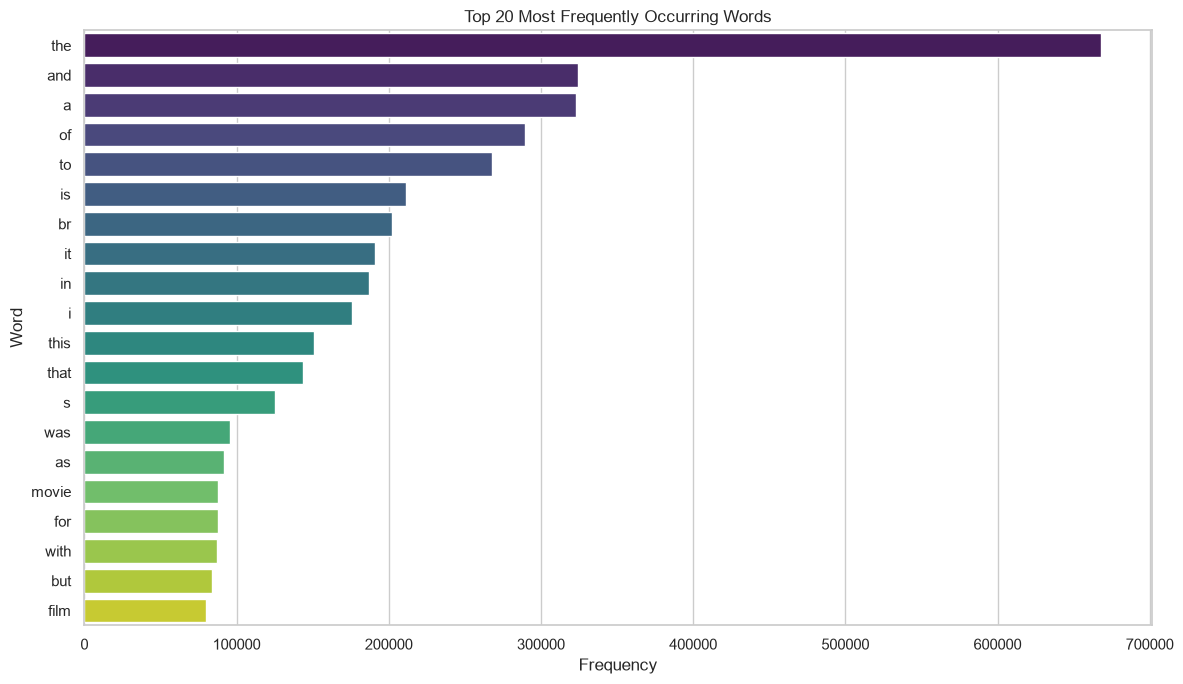

In [14]:
# Prepare data for visualization
word_freq_df = pd.DataFrame(
    most_common_words,
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=word_freq_df,
    x="Frequency",
    y="Word",
    hue="Word",
    palette="viridis",
    legend=False
)

plt.title("Top 20 Most Frequently Occurring Words")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "04_top_20_frequent_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Visualization Findings

The top 20 word-frequency visualization reveals that common English stopwords dominate the dataset vocabulary.

The presence of `br` highlights the impact of unprocessed HTML formatting, while `s` indicates tokenization issues involving apostrophes.

Movie-related words such as `movie` and `film` are also among the frequently occurring terms.

This analysis establishes the need for HTML removal, text normalization, and appropriate tokenization before model development.

In [15]:
# Separate positive and negative reviews
positive_reviews = df.loc[
    df["sentiment"] == "positive", "review"
]

negative_reviews = df.loc[
    df["sentiment"] == "negative", "review"
]

# Combine reviews separately
positive_text = " ".join(positive_reviews).lower()
negative_text = " ".join(negative_reviews).lower()

# Extract words
positive_words = re.findall(r"\b[a-z]+\b", positive_text)
negative_words = re.findall(r"\b[a-z]+\b", negative_text)

# Calculate word frequencies
positive_word_counts = Counter(positive_words)
negative_word_counts = Counter(negative_words)

# Display top 15 words for each sentiment
print("TOP 15 WORDS IN POSITIVE REVIEWS\n")

for word, count in positive_word_counts.most_common(15):
    print(f"{word}: {count}")

print("\nTOP 15 WORDS IN NEGATIVE REVIEWS\n")

for word, count in negative_word_counts.most_common(15):
    print(f"{word}: {count}")

TOP 15 WORDS IN POSITIVE REVIEWS

the: 341281
and: 176634
a: 164323
of: 152105
to: 131322
is: 111830
in: 99250
br: 97954
it: 95133
i: 81997
this: 69648
that: 69593
s: 64675
as: 51106
with: 45718

TOP 15 WORDS IN NEGATIVE REVIEWS

the: 326712
a: 158647
and: 147807
of: 137305
to: 136802
br: 103997
is: 99252
it: 95724
i: 93636
in: 87531
this: 81354
that: 74286
s: 60333
was: 52269
movie: 50117


In [16]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

print("Total English Stopwords:", len(stop_words))
print("\nSample Stopwords:")
print(list(stop_words)[:20])

Total English Stopwords: 198

Sample Stopwords:
["she's", 'out', 'is', 'too', "shouldn't", "should've", 'll', 'while', 'only', "don't", 'mustn', "they'd", 'an', 'how', 'hasn', 'all', 'mightn', 'from', 'me', 'been']


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\akhil\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [17]:
import re
from collections import Counter
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def extract_meaningful_words(text):
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Extract alphabetic words
    words = re.findall(r"\b[a-z]+\b", text)

    # Remove stopwords
    words = [
        word for word in words
        if word not in stop_words
    ]

    return words


# Extract words separately for each sentiment
positive_words_clean = []

for review in positive_reviews:
    positive_words_clean.extend(
        extract_meaningful_words(review)
    )


negative_words_clean = []

for review in negative_reviews:
    negative_words_clean.extend(
        extract_meaningful_words(review)
    )


# Calculate frequencies
positive_counts = Counter(positive_words_clean)
negative_counts = Counter(negative_words_clean)


# Display top 20 words
print("TOP 20 WORDS IN POSITIVE REVIEWS\n")

for word, count in positive_counts.most_common(20):
    print(f"{word}: {count}")


print("\nTOP 20 WORDS IN NEGATIVE REVIEWS\n")

for word, count in negative_counts.most_common(20):
    print(f"{word}: {count}")

TOP 20 WORDS IN POSITIVE REVIEWS

film: 42110
movie: 37854
one: 27320
like: 17714
good: 15025
great: 12964
story: 12934
time: 12752
well: 12729
see: 12276
also: 10793
really: 10739
would: 10595
even: 9617
first: 9230
much: 9201
people: 8719
love: 8692
best: 8510
get: 8285

TOP 20 WORDS IN NEGATIVE REVIEWS

movie: 50116
film: 37595
one: 26283
like: 22458
even: 15254
good: 14728
bad: 14726
would: 14007
time: 12357
really: 12355
see: 10753
story: 10185
get: 10136
much: 10117
people: 9469
make: 9354
could: 9299
made: 8801
well: 8539
first: 8353


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare a sample of positive and negative reviews
positive_sample = positive_reviews.sample(
    n=5000,
    random_state=42
)

negative_sample = negative_reviews.sample(
    n=5000,
    random_state=42
)

# Combine samples
sample_reviews = pd.concat(
    [positive_sample, negative_sample]
)

# TF-IDF vectorizer
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    min_df=5
)

# Fit and transform reviews
tfidf_matrix = tfidf.fit_transform(sample_reviews)

# Extract vocabulary and average TF-IDF scores
feature_names = tfidf.get_feature_names_out()

mean_tfidf = np.asarray(
    tfidf_matrix.mean(axis=0)
).flatten()

# Create DataFrame
tfidf_scores = pd.DataFrame({
    "word": feature_names,
    "mean_tfidf": mean_tfidf
})

# Display top 20 terms
top_tfidf_words = tfidf_scores.sort_values(
    by="mean_tfidf",
    ascending=False
).head(20)

display(top_tfidf_words)

,word,mean_tfidf
525,br,0.108646
2969,movie,0.056147
532,br br,0.054402
1711,film,0.048514
2624,like,0.026908
2445,just,0.025893
1958,good,0.023485
4522,time,0.020330
4255,story,0.019915
3618,really,0.019852


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
import re

# Clean HTML tags
def clean_html(text):
    text = re.sub(r"<[^>]+>", " ", text)
    return text


# Clean sampled reviews
cleaned_sample_reviews = sample_reviews.apply(clean_html)

# Initialize TF-IDF
tfidf_clean = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    min_df=5
)

# Transform cleaned reviews
tfidf_matrix_clean = tfidf_clean.fit_transform(
    cleaned_sample_reviews
)

# Calculate average TF-IDF scores
feature_names_clean = tfidf_clean.get_feature_names_out()

mean_tfidf_clean = np.asarray(
    tfidf_matrix_clean.mean(axis=0)
).flatten()

# Create results DataFrame
tfidf_scores_clean = pd.DataFrame({
    "word": feature_names_clean,
    "mean_tfidf": mean_tfidf_clean
})

# Display top 20 terms
display(
    tfidf_scores_clean.sort_values(
        by="mean_tfidf",
        ascending=False
    ).head(20)
)

,word,mean_tfidf
2946,movie,0.057251
1671,film,0.049440
2595,like,0.027474
2414,just,0.026445
1921,good,0.023978
4518,time,0.020759
4247,story,0.020310
3606,really,0.020288
352,bad,0.019153
1966,great,0.018770


In [20]:
# Separate cleaned positive and negative reviews

positive_sample_clean = positive_sample.apply(clean_html)
negative_sample_clean = negative_sample.apply(clean_html)

# Transform both groups using the same fitted vectorizer

positive_tfidf = tfidf_clean.transform(
    positive_sample_clean
)

negative_tfidf = tfidf_clean.transform(
    negative_sample_clean
)

# Calculate average TF-IDF scores for each sentiment

positive_mean = np.asarray(
    positive_tfidf.mean(axis=0)
).flatten()

negative_mean = np.asarray(
    negative_tfidf.mean(axis=0)
).flatten()

# Create comparison DataFrame

sentiment_tfidf_comparison = pd.DataFrame({
    "word": feature_names_clean,
    "positive_tfidf": positive_mean,
    "negative_tfidf": negative_mean
})

# Calculate difference

sentiment_tfidf_comparison["difference"] = (
    sentiment_tfidf_comparison["positive_tfidf"]
    - sentiment_tfidf_comparison["negative_tfidf"]
)

# Top 20 relatively positive-associated terms

print("TOP 20 POSITIVE-ASSOCIATED TERMS")

display(
    sentiment_tfidf_comparison.sort_values(
        by="difference",
        ascending=False
    ).head(20)
)

# Top 20 relatively negative-associated terms

print("TOP 20 NEGATIVE-ASSOCIATED TERMS")

display(
    sentiment_tfidf_comparison.sort_values(
        by="difference",
        ascending=True
    ).head(20)
)

TOP 20 POSITIVE-ASSOCIATED TERMS


,word,positive_tfidf,negative_tfidf,difference
1966,great,0.027149,0.010391,0.016758
2692,love,0.020457,0.009316,0.011141
433,best,0.019590,0.008956,0.010634
1509,excellent,0.010777,0.002369,0.008408
4917,wonderful,0.008859,0.001688,0.007171
404,beautiful,0.009527,0.003042,0.006486
2697,loved,0.008815,0.002389,0.006426
2587,life,0.016010,0.010120,0.005890
3277,perfect,0.007731,0.002013,0.005718
205,amazing,0.007153,0.001751,0.005401


TOP 20 NEGATIVE-ASSOCIATED TERMS


,word,positive_tfidf,negative_tfidf,difference
352,bad,0.006879,0.031427,-0.024549
2946,movie,0.050231,0.064271,-0.014040
4942,worst,0.001232,0.014994,-0.013762
2414,just,0.021122,0.031768,-0.010647
344,awful,0.001082,0.010842,-0.009760
4824,waste,0.000464,0.010092,-0.009627
4445,terrible,0.001210,0.010471,-0.009261
3359,plot,0.009769,0.018856,-0.009086
4295,stupid,0.001423,0.010026,-0.008603
99,acting,0.010523,0.018781,-0.008258


## 7. Positive vs. Negative Vocabulary Analysis

### Objective

The objective of this analysis is to identify vocabulary differences between positive and negative movie reviews using class-specific average TF-IDF scores.

### Positive-Associated Vocabulary

The analysis identified several terms with higher average TF-IDF scores in positive reviews:

* great
* love
* best
* excellent
* wonderful
* beautiful
* perfect
* amazing
* brilliant
* enjoyed

These terms are generally associated with appreciation, satisfaction, and positive opinions.

### Negative-Associated Vocabulary

Several terms had higher average TF-IDF scores in negative reviews:

* bad
* worst
* awful
* waste
* terrible
* stupid
* poor
* boring
* horrible
* worse

These terms are generally associated with dissatisfaction, criticism, and negative opinions.

### Key Findings

1. Positive and negative reviews exhibit distinguishable vocabulary patterns.
2. Strongly sentiment-associated terms show noticeable differences in average TF-IDF scores.
3. Some frequently occurring terms, such as movie and film, are not necessarily sentiment indicators.
4. Class-specific TF-IDF comparison provides more useful insights than examining overall word frequencies.

### Conclusion

The vocabulary analysis demonstrates that movie reviews contain identifiable sentiment-related linguistic patterns.

These findings support the use of TF-IDF as a feature extraction technique for our binary sentiment classification models.

**Note:** These findings represent exploratory associations from a 5,000-review sample per sentiment class. They do not independently establish predictive performance.

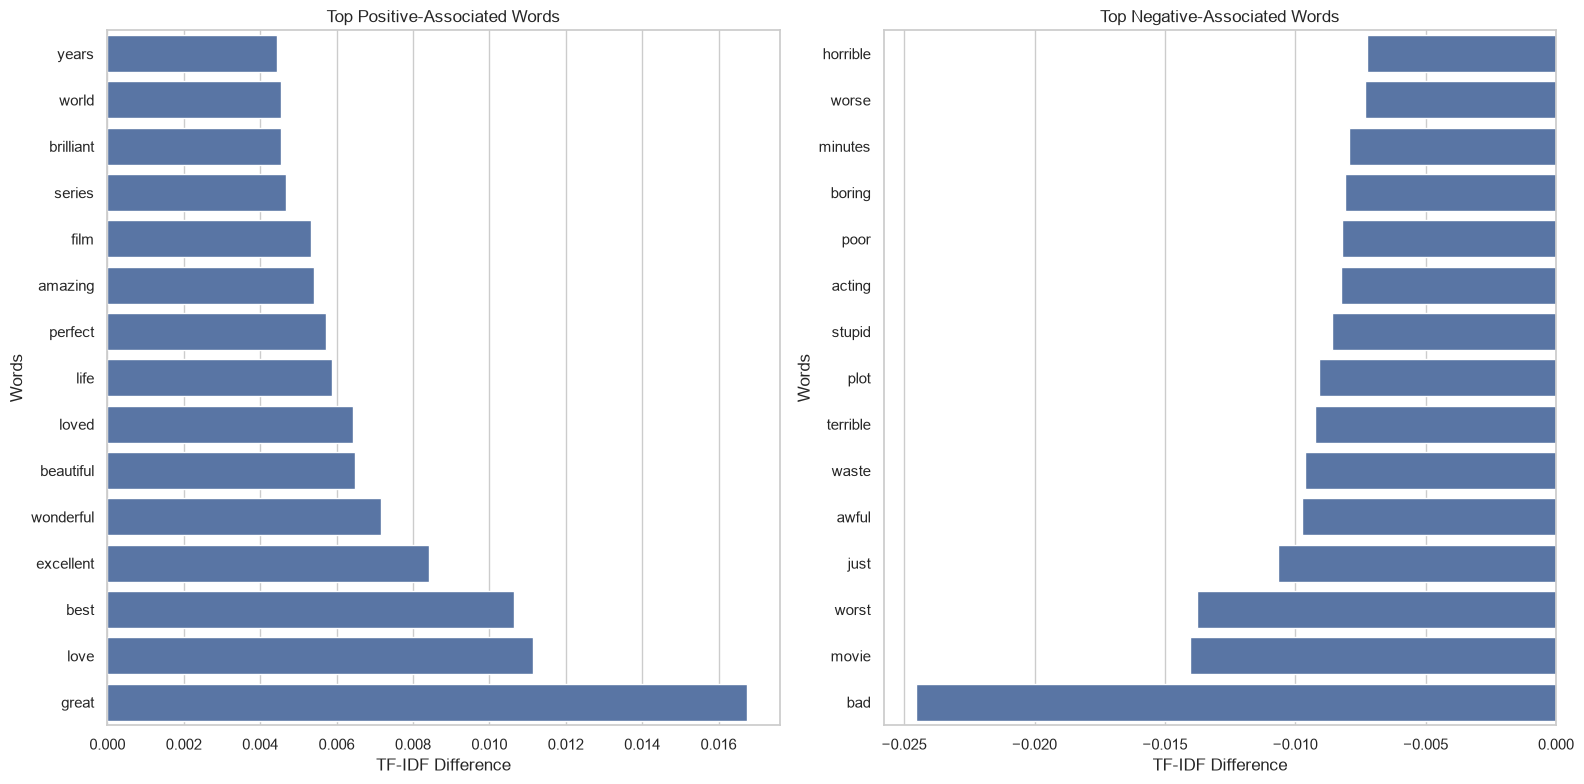

In [21]:
# Select top 15 positive-associated words
top_positive = (
    sentiment_tfidf_comparison
    .sort_values("difference", ascending=False)
    .head(15)
    .sort_values("difference")
)

# Select top 15 negative-associated words
top_negative = (
    sentiment_tfidf_comparison
    .sort_values("difference", ascending=True)
    .head(15)
    .sort_values("difference", ascending=False)
)

# Create side-by-side visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Positive-associated vocabulary
sns.barplot(
    data=top_positive,
    x="difference",
    y="word",
    ax=axes[0]
)

axes[0].set_title("Top Positive-Associated Words")
axes[0].set_xlabel("TF-IDF Difference")
axes[0].set_ylabel("Words")

# Negative-associated vocabulary
sns.barplot(
    data=top_negative,
    x="difference",
    y="word",
    ax=axes[1]
)

axes[1].set_title("Top Negative-Associated Words")
axes[1].set_xlabel("TF-IDF Difference")
axes[1].set_ylabel("Words")

plt.tight_layout()

# Save visualization
plt.savefig(
    IMAGE_DIR / "05_sentiment_vocabulary_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Visualization Findings

The comparison of positive-associated and negative-associated vocabulary reveals distinct linguistic patterns.

**Positive-associated terms:**
Great, love, best, excellent, wonderful, beautiful, perfect, and amazing.

**Negative-associated terms:**
Bad, worst, awful, waste, terrible, boring, poor, and horrible.

### Key Observations

* Positive reviews contain more prominent expressions of appreciation and satisfaction.
* Negative reviews contain more prominent expressions of criticism and dissatisfaction.
* The word "great" has the strongest positive association in the analyzed sample.
* The word "bad" has the strongest negative association in the analyzed sample.

### Conclusion

The visualization demonstrates meaningful differences in vocabulary usage between positive and negative movie reviews. These patterns support the application of TF-IDF feature extraction for sentiment classification.

The observed differences are exploratory associations and should be validated through model training and evaluation.